# Comparación de Modelos - Predicción Univariable del tipo de cambio CRC/USD (Ventas)

Se exploran algunos modelos y sus rendimientos sin el uso de covariables, más adelante se harán experimentos en donde se incluyan dichas variables, (tasas de interés, inflación, actividad económica, reservas internacionales, entre otras).

In [22]:
from bccr import SW 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

from darts import TimeSeries
from darts.metrics import mape, rmse, mae

In [23]:
df = pd.read_csv('flotacion_data_13_10_2026.csv', index_col=0, parse_dates=True)

In [24]:
df_ventas = df[['venta']]
df_ventas.head()

,venta
2015-01-30,542.64
2015-01-31,543.08
2015-02-01,543.08
2015-02-02,543.08
2015-02-03,543.16


In [25]:
ts = TimeSeries.from_dataframe(df_ventas, value_cols="venta")
train, val = ts.split_before(pd.Timestamp('2026-10-01'))

In [65]:
#Estandarizar datos, para algunos modelos esta forma de datos es lo optimo o recomendado
from darts.dataprocessing.transformers import Scaler
scaler = Scaler()

train_scaled = scaler.fit_transform(train)
val_scaled = scaler.transform(val)

## Metodos estadisticos

### NaiveDrift

In [27]:
from darts.models import NaiveDrift

model_drift = NaiveDrift()

model_drift.fit(train_scaled)
drift_forecast_scaled = model_drift.predict(len(val_scaled))

# Return prediction to original units
forecast_drift = scaler.inverse_transform(drift_forecast_scaled)

print("MAPE:", mape(val, forecast_drift))
print("RMSE:", rmse(val, forecast_drift))
print("MAE:", mae(val, forecast_drift))

MAPE: 0.7018160313031857
RMSE: 3.328204389883022
MAE: 3.2408370492059455


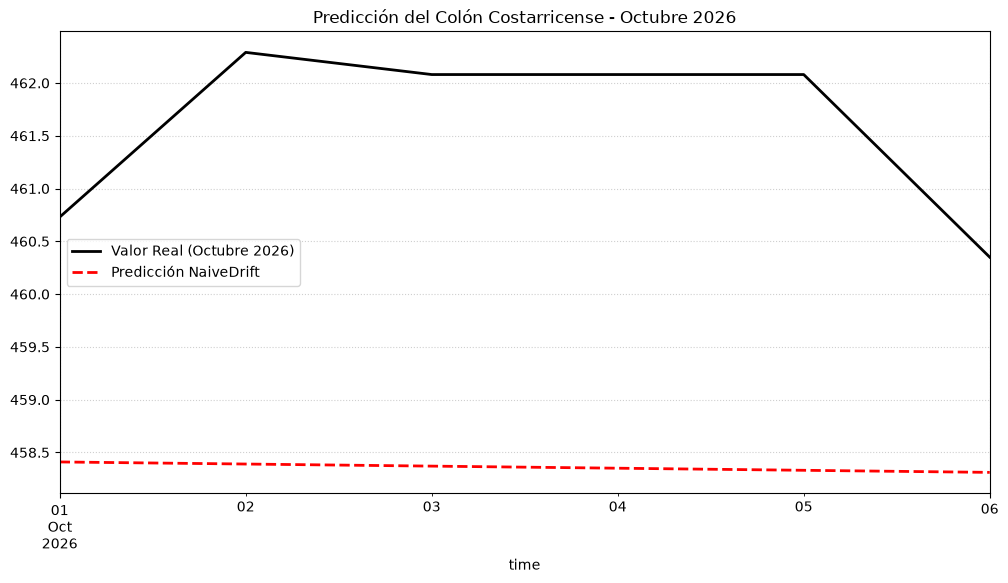

In [43]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_drift.plot(label="Predicción NaiveDrift", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### ARIMA

In [45]:
from darts.models import ARIMA
#Se recomienda usar los datos sin "normalizar"
model_arima = ARIMA(p=1, d=1, q=0) #Mejor comb de parametros encontrada
model_arima.fit(train)
forecast_arima = model_arima.predict(len(val))

print("MAPE:", mape(val, forecast_arima))
print("RMSE:", rmse(val, forecast_arima))
print("MAE:", mae(val, forecast_arima))

MAPE: 0.5181336246128275
RMSE: 2.503258940608943
MAE: 2.392905047230954


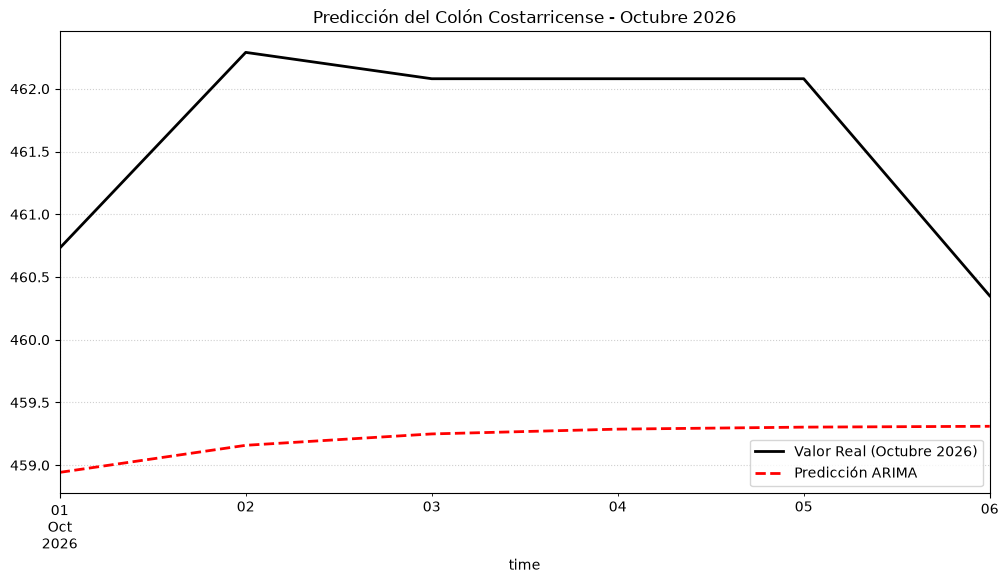

In [46]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_arima.plot(label="Predicción ARIMA", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### AutoARIMA 

In [47]:
from darts.models import AutoARIMA

model_autoArima = AutoARIMA()

model_autoArima.fit(train)

forecast_autoArima = model_autoArima.predict(n=len(val))

print("MAPE:", mape(val, forecast_autoArima))
print("RMSE:", rmse(val, forecast_autoArima))
print("MAE:", mae(val, forecast_autoArima))


MAPE: 0.5702049358289403
RMSE: 2.725228150989274
MAE: 2.6332281469798127


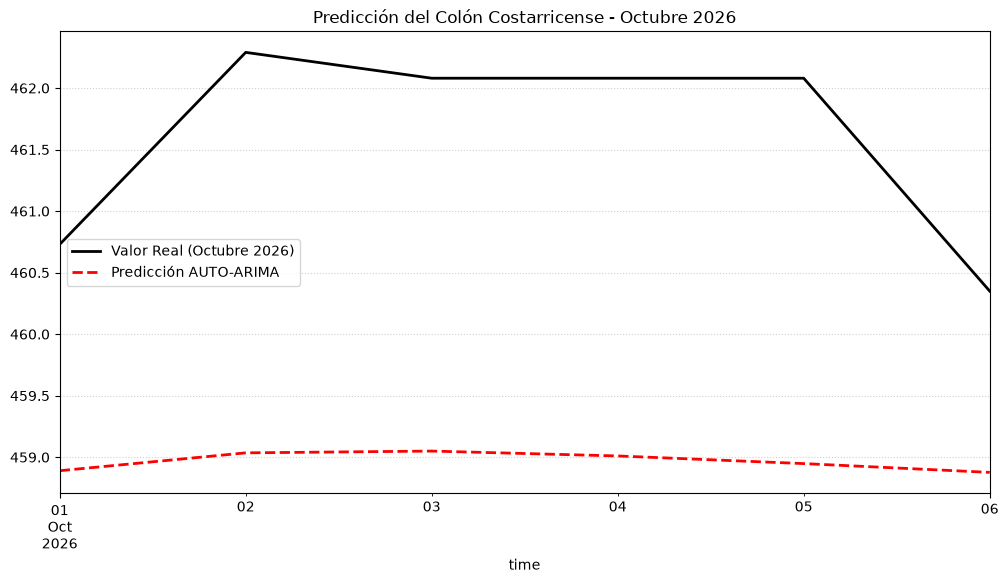

In [48]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_autoArima.plot(label="Predicción AUTO-ARIMA", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### Exponential Smoothing

In [63]:
from darts.models import ExponentialSmoothing

model_expSmooth = ExponentialSmoothing()
model_expSmooth.fit(train)
forecast_expSmooth = model_expSmooth.predict(n=len(val))

print("MAPE:", mape(val, forecast_expSmooth))
print("RMSE:", rmse(val, forecast_expSmooth))
print("MAE:", mae(val, forecast_expSmooth))

MAPE: 0.36490070637380007
RMSE: 2.151506928827739
MAE: 1.68290046491425


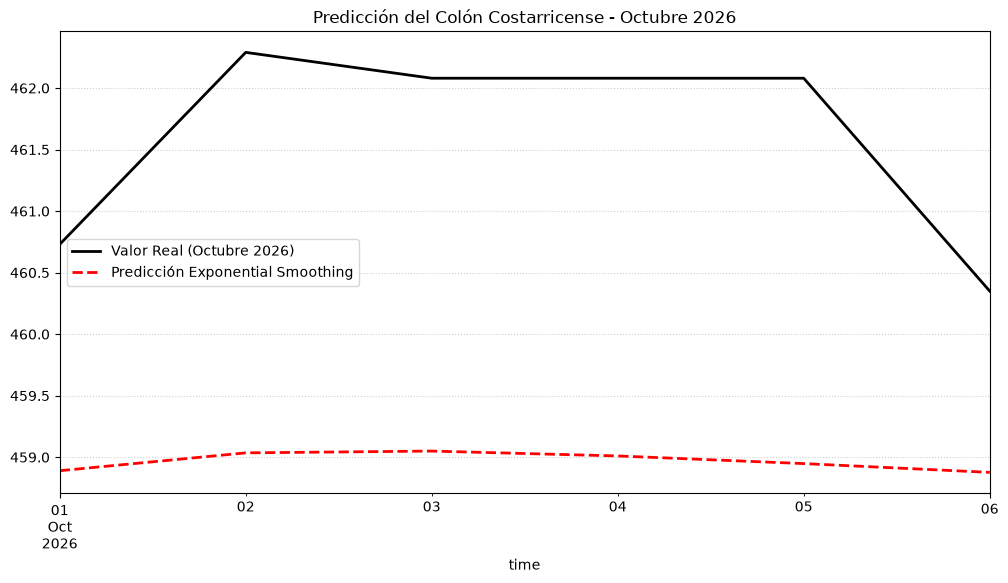

In [64]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_autoArima.plot(label="Predicción Exponential Smoothing", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

## Machine Learning

### XGBoost

In [60]:
from darts.models import XGBModel

model_XGB = XGBModel(
    lags=5, #Si le pongo 5 dias (time_steps) las metricas dan resultados mas optimos
    output_chunk_length=7
)

model_XGB.fit(train)
forecast_XGB = model_XGB.predict(n=len(val))

print("MAPE:", mape(val, forecast_XGB))
print("RMSE:", rmse(val, forecast_XGB))
print("MAE:", mae(val, forecast_XGB))

MAPE: 0.17641183351391065
RMSE: 0.9031805544013556
MAE: 0.8143107096354166


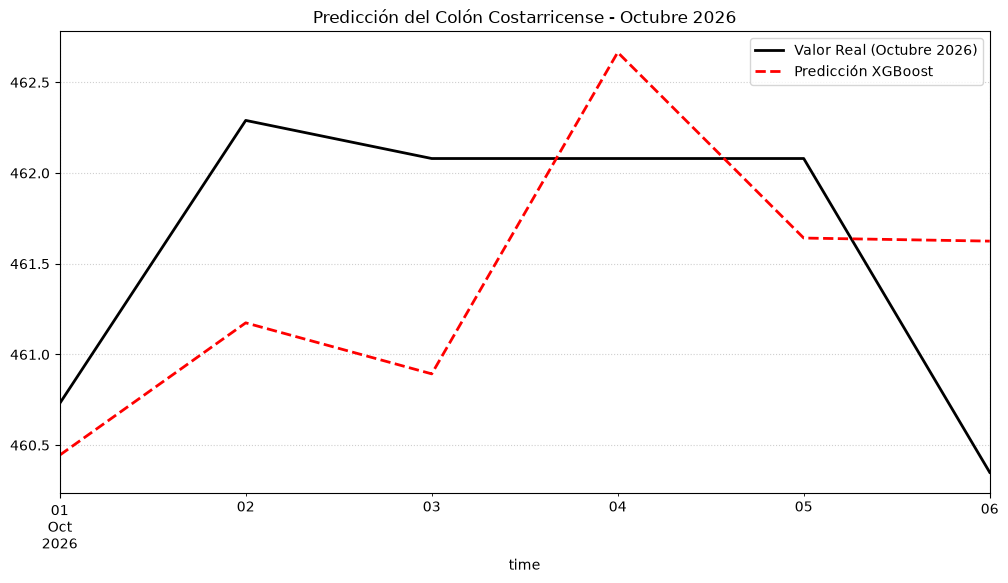

In [61]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_XGB.plot(label="Predicción XGBoost", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

## Deep Learning

### Vanilla RNN 

In [66]:
from darts.models import RNNModel

model_RNN = RNNModel(
    model="RNN",
    input_chunk_length=30,
    training_length=50,
    hidden_dim=25,
    n_rnn_layers=1,
    dropout=0.0,
    n_epochs=100,
    batch_size=32,
    random_state=42
)
model_RNN.fit(train_scaled)

RNN_forecast_scaled = model_RNN.predict(len(val_scaled))
forecast_RNN = scaler.inverse_transform(RNN_forecast_scaled)

print("MAPE:", mape(val, forecast_RNN))
print("RMSE:", rmse(val, forecast_RNN))
print("MAE:", mae(val, forecast_RNN))

/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | rnn             | RNN              | 700    | train
6 | V               | Linear           | 26     | train
------------------------------------------

Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=100` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Predicting: |                                                                                                 …

MAPE: 0.7453180479715688
RMSE: 3.5205929210303863
MAE: 3.4415877193543167


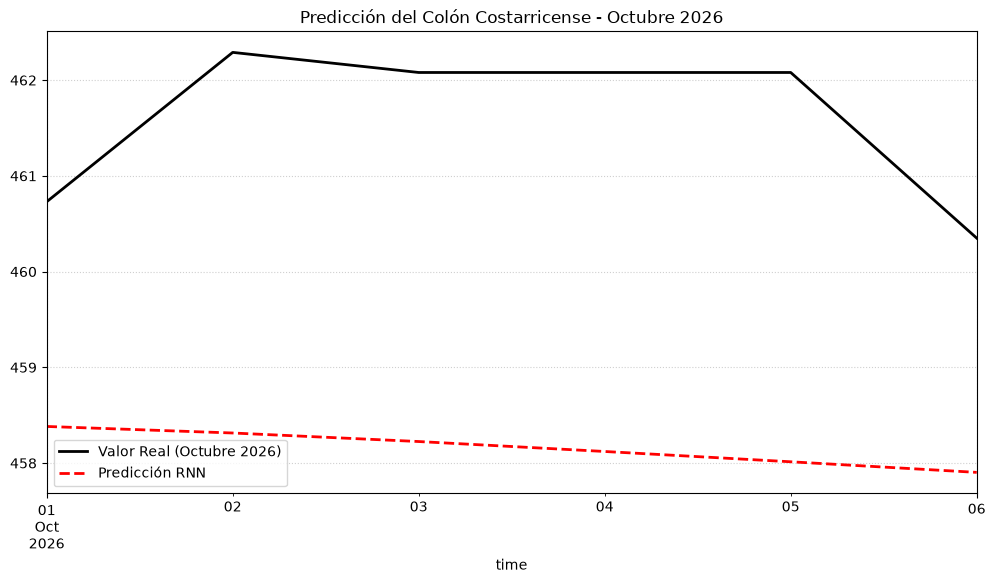

In [67]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_RNN.plot(label="Predicción RNN", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### LSTM

In [68]:
model_LSTM = RNNModel(
    model="LSTM",
    input_chunk_length=30,
    training_length=50,
    hidden_dim=25,
    n_rnn_layers=1,
    dropout=0.0,
    n_epochs=100,
    batch_size=32,
    random_state=42
)
model_LSTM.fit(train_scaled)

LSTM_forecast_scaled = model_LSTM.predict(len(val_scaled))
forecast_LSTM = scaler.inverse_transform(LSTM_forecast_scaled)

print("MAPE:", mape(val, forecast_LSTM))
print("RMSE:", rmse(val, forecast_LSTM))
print("MAE:", mae(val, forecast_LSTM))

/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | rnn             | LSTM             | 2.8 K  | train
6 | V               | Linear           | 26     | train
------------------------------------------

Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=100` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Predicting: |                                                                                                 …

MAPE: 0.42614431188804547
RMSE: 2.17638663663449
MAE: 1.9683852300674214


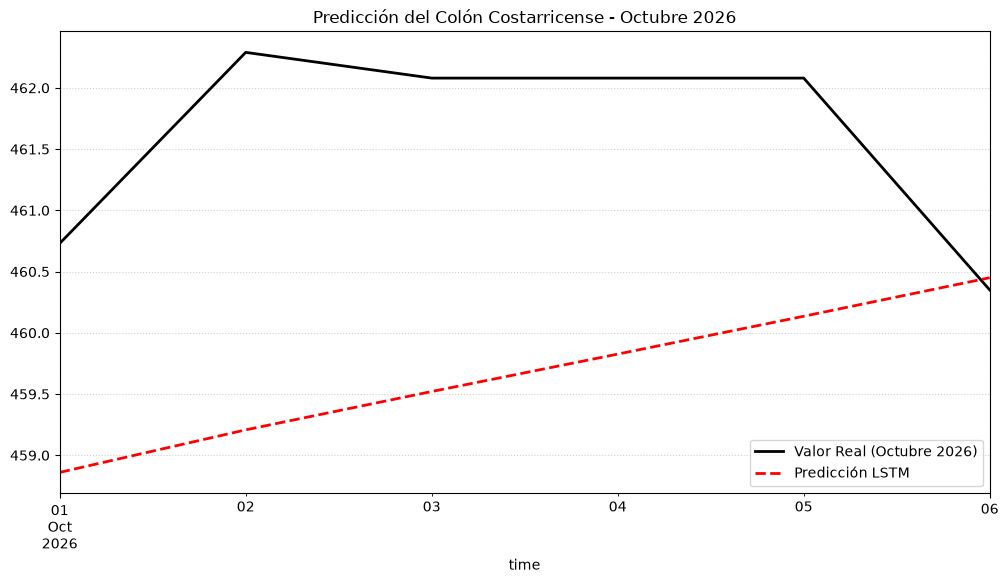

In [71]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_LSTM.plot(label="Predicción LSTM", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### GRU

In [69]:
model_GRU = RNNModel(
    model="GRU",
    input_chunk_length=30,
    training_length=50,
    hidden_dim=25,
    n_rnn_layers=1,
    dropout=0.0,
    n_epochs=100,
    batch_size=32,
    random_state=42
)
model_GRU.fit(train_scaled)

GRU_forecast_scaled = model_GRU.predict(len(val_scaled))
forecast_GRU = scaler.inverse_transform(GRU_forecast_scaled)

print("MAPE:", mape(val, forecast_GRU))
print("RMSE:", rmse(val, forecast_GRU))
print("MAE:", mae(val, forecast_GRU))

/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | rnn             | GRU              | 2.1 K  | train
6 | V               | Linear           | 26     | train
------------------------------------------

Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=100` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Predicting: |                                                                                                 …

MAPE: 0.6966395533629015
RMSE: 3.297011635327355
MAE: 3.2168131615258915


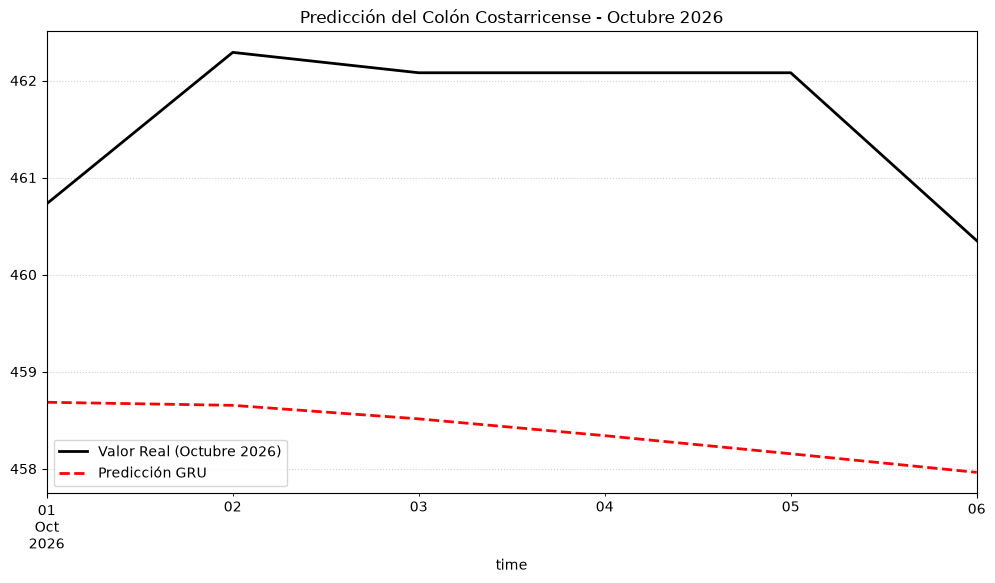

In [72]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_GRU.plot(label="Predicción GRU", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### TFT

In [70]:
from darts.models import TFTModel

model_TFT = TFTModel(
    input_chunk_length=30,
    output_chunk_length=7,
    add_relative_index=True,
    n_epochs=100,
    random_state=42
)

model_TFT.fit(train_scaled)
TFT_forecast_scaled = model.predict(n=len(val_scaled))
forecast_TFT = scaler.inverse_transform(TFT_forecast_scaled)

print("MAPE:", mape(val, forecast_TFT))
print("RMSE:", rmse(val, forecast_TFT))
print("MAE:", mae(val, forecast_TFT))

/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/gustavo/Documents/Proyectos/env/lib/python3.14/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

   | Name                              | Type                             | Params | Mode 
------------------------------------------------------------------------------------------------
0  | train_metrics                     | MetricCollection                 | 0      | train
1  | val_metrics                       | MetricCollection                 | 0      | train
2  | input_embeddings                  | _MultiEmbedding                  | 0      | train
3  | static_covariates_vsn             | _VariableSelectionNetwork        | 0      | train


Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=100` reached.


MAPE: 0.7018160313031857
RMSE: 3.328204389883022
MAE: 3.2408370492059455


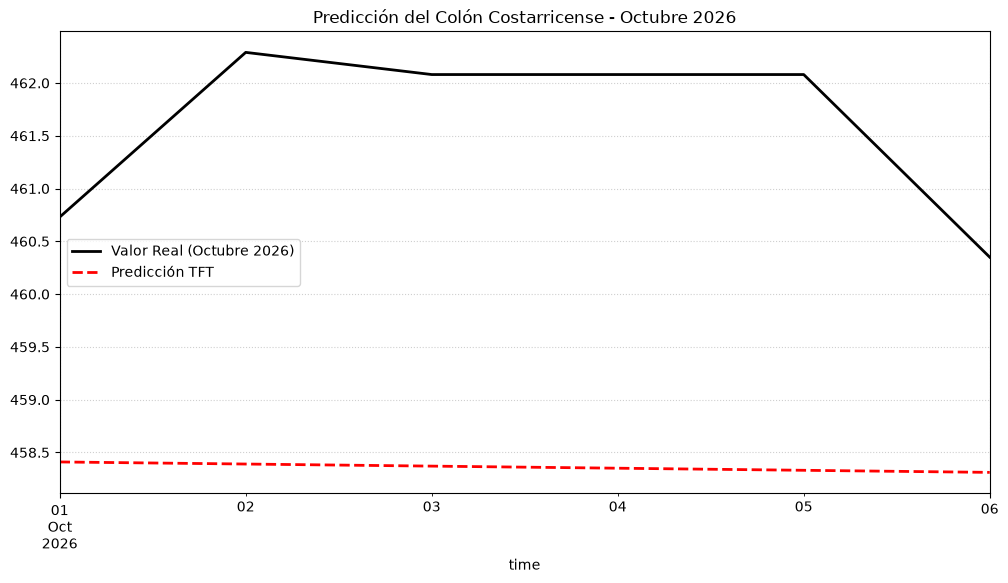

In [73]:
#Visual
plt.figure(figsize=(12, 6))

val.plot(label="Valor Real (Octubre 2026)", color="black", lw=2)

# Graficamos la predicción encima
forecast_TFT.plot(label="Predicción TFT", color="red", linestyle="--")

plt.title("Predicción del Colón Costarricense - Octubre 2026")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()